In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
df = pd.read_csv(r'C:\Users\LENOVO\OneDrive\Desktop\palak\project 4\archive\Bank Customer Churn Prediction.csv', encoding= 'unicode_escape')
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [11]:
df.shape

(10000, 12)

In [13]:
df.columns

Index(['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure',
       'balance', 'products_number', 'credit_card', 'active_member',
       'estimated_salary', 'churn'],
      dtype='object')

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [15]:
df.isnull().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [16]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [17]:
print("Duplicate customer IDs:", df['customer_id'].duplicated().sum())

Duplicate customer IDs: 0


In [18]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
credit_score,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
products_number,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
credit_card,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
active_member,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
estimated_salary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48
churn,10000.0,2.037000e-01,0.402769,0.00,0.00,0.000000e+00,0.000000e+00,1.00


In [19]:
print("Minimum age:", df['age'].min())
print("Maximum age:", df['age'].max())

print("\nCustomers below 18:", (df['age'] < 18).sum())
print("Customers above 85:", (df['age'] > 85).sum())

Minimum age: 18
Maximum age: 92

Customers below 18: 0
Customers above 85: 3


In [20]:
print(df['products_number'].value_counts().sort_index())

1    5084
2    4590
3     266
4      60
Name: products_number, dtype: int64


In [21]:
df['tenure'].value_counts().sort_index()

0      413
1     1035
2     1048
3     1009
4      989
5     1012
6      967
7     1028
8     1025
9      984
10     490
Name: tenure, dtype: int64

In [22]:
for col in ['country', 'gender', 'credit_card', 'active_member', 'churn']:
    print(f"\n{col.upper()}")
    print(df[col].value_counts())


COUNTRY
France     5014
Germany    2509
Spain      2477
Name: country, dtype: int64

GENDER
Male      5457
Female    4543
Name: gender, dtype: int64

CREDIT_CARD
1    7055
0    2945
Name: credit_card, dtype: int64

ACTIVE_MEMBER
1    5151
0    4849
Name: active_member, dtype: int64

CHURN
0    7963
1    2037
Name: churn, dtype: int64


In [23]:
churn_df = df.copy()

print("Working copy created successfully!")
print("Original dataset:", df.shape)
print("Working dataset:", churn_df.shape)

Working copy created successfully!
Original dataset: (10000, 12)
Working dataset: (10000, 12)


In [24]:
age_bins = [17, 24, 34, 44, 54, float('inf')]

age_labels = [
    'Under 25',
    '25-34',
    '35-44',
    '45-54',
    '55+'
]

churn_df['age_group'] = pd.cut(
    churn_df['age'],
    bins=age_bins,
    labels=age_labels
)

churn_df['age_group'].value_counts().sort_index()

Under 25     457
25-34       3222
35-44       3981
45-54       1458
55+          882
Name: age_group, dtype: int64

In [25]:
tenure_bins = [-1, 2, 5, 8, 10]

tenure_labels = [
    '0-2 Years',
    '3-5 Years',
    '6-8 Years',
    '9-10 Years'
]

churn_df['tenure_group'] = pd.cut(
    churn_df['tenure'],
    bins=tenure_bins,
    labels=tenure_labels
)

churn_df['tenure_group'].value_counts().sort_index()

0-2 Years     2496
3-5 Years     3010
6-8 Years     3020
9-10 Years    1474
Name: tenure_group, dtype: int64

In [26]:
churn_df['product_segment'] = churn_df['products_number'].map({
    1: 'Single Product',
    2: 'Two Products',
    3: 'Three Products',
    4: 'Four Products'
})

churn_df['product_segment'].value_counts()

Single Product    5084
Two Products      4590
Three Products     266
Four Products       60
Name: product_segment, dtype: int64

In [27]:
positive_balance = churn_df.loc[
    churn_df['balance'] > 0, 'balance'
]

q1 = positive_balance.quantile(1/3)
q2 = positive_balance.quantile(2/3)

churn_df['balance_segment'] = np.select(
    [
        churn_df['balance'] == 0,
        churn_df['balance'] <= q1,
        churn_df['balance'] <= q2
    ],
    [
        'Zero Balance',
        'Low Balance',
        'Medium Balance'
    ],
    default='High Balance'
)

churn_df['balance_segment'].value_counts()

Zero Balance      3617
High Balance      2128
Low Balance       2128
Medium Balance    2127
Name: balance_segment, dtype: int64

In [28]:
new_columns = [
    'age_group',
    'tenure_group',
    'product_segment',
    'balance_segment'
]

display(churn_df[new_columns].head(10))

,age_group,tenure_group,product_segment,balance_segment
0,35-44,0-2 Years,Single Product,Zero Balance
1,35-44,0-2 Years,Single Product,Low Balance
2,35-44,6-8 Years,Three Products,High Balance
3,35-44,0-2 Years,Two Products,Zero Balance
4,35-44,0-2 Years,Single Product,Medium Balance
5,35-44,6-8 Years,Two Products,Medium Balance
6,45-54,6-8 Years,Two Products,Zero Balance
7,25-34,3-5 Years,Four Products,Medium Balance
8,35-44,3-5 Years,Two Products,High Balance
9,25-34,0-2 Years,Single Product,High Balance


In [29]:
age_analysis = churn_df.groupby(
    'age_group',
    observed=False
).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum')
)

age_analysis['retained_customers'] = (
    age_analysis['total_customers'] -
    age_analysis['churned_customers']
)

age_analysis['churn_rate'] = (
    age_analysis['churned_customers'] /
    age_analysis['total_customers'] * 100
)

age_analysis['churn_contribution'] = (
    age_analysis['churned_customers'] /
    churn_df['churn'].sum() * 100
)

age_analysis = age_analysis.round(2)

display(age_analysis)

,total_customers,churned_customers,retained_customers,churn_rate,churn_contribution
age_group,,,,,
Under 25,457,40,417,8.75,1.96
25-34,3222,250,2972,7.76,12.27
35-44,3981,703,3278,17.66,34.51
45-54,1458,702,756,48.15,34.46
55+,882,342,540,38.78,16.79


In [31]:
product_analysis = churn_df.groupby(
    'product_segment',
    observed=False
).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum')
)

product_analysis['retained_customers'] = (
    product_analysis['total_customers'] -
    product_analysis['churned_customers']
)

product_analysis['churn_rate'] = (
    product_analysis['churned_customers'] /
    product_analysis['total_customers'] * 100
)

product_analysis['churn_contribution'] = (
    product_analysis['churned_customers'] /
    churn_df['churn'].sum() * 100
)

display(product_analysis.round(2))

,total_customers,churned_customers,retained_customers,churn_rate,churn_contribution
product_segment,,,,,
Four Products,60,60,0,100.00,2.95
Single Product,5084,1409,3675,27.71,69.17
Three Products,266,220,46,82.71,10.80
Two Products,4590,348,4242,7.58,17.08


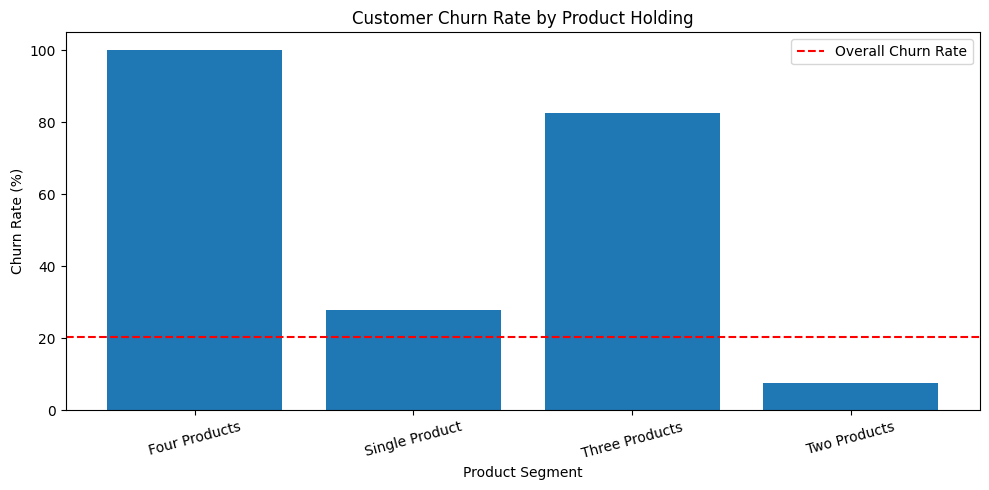

In [35]:

plt.figure(figsize=(10, 5))

plt.bar(
    product_analysis.index.astype(str),
    product_analysis['churn_rate']
)

# Show overall churn rate for comparison
plt.axhline(
    y=churn_df['churn'].mean() * 100,
    color='red',
    linestyle='--',
    label='Overall Churn Rate'
)

plt.title('Customer Churn Rate by Product Holding')
plt.xlabel('Product Segment')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()


In [37]:

geography_analysis = churn_df.groupby('country').agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum')
)

geography_analysis['retained_customers'] = (
    geography_analysis['total_customers'] -
    geography_analysis['churned_customers']
)

geography_analysis['churn_rate'] = (
    geography_analysis['churned_customers'] /
    geography_analysis['total_customers']
) * 100

geography_analysis['churn_contribution'] = (
    geography_analysis['churned_customers'] /
    churn_df['churn'].sum()
) * 100

display(geography_analysis.round(2))


,total_customers,churned_customers,retained_customers,churn_rate,churn_contribution
country,,,,,
France,5014,810,4204,16.15,39.76
Germany,2509,814,1695,32.44,39.96
Spain,2477,413,2064,16.67,20.27


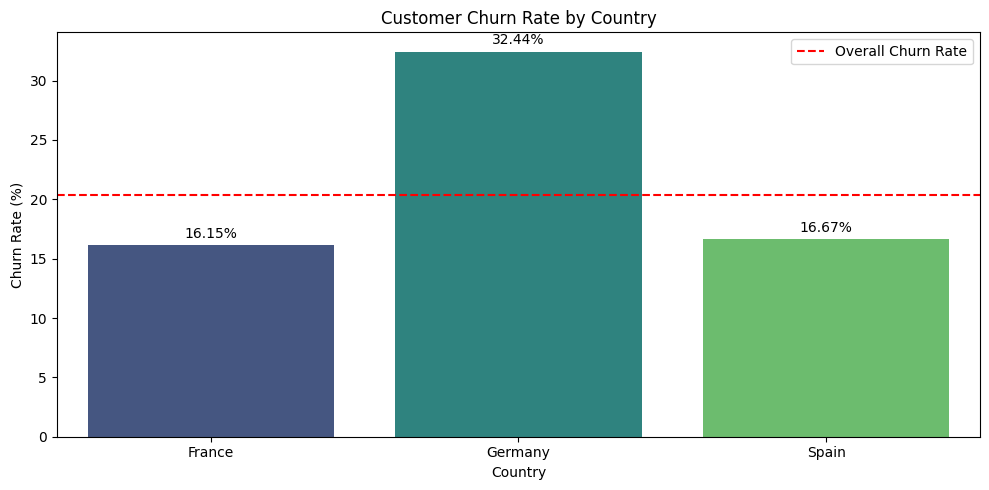

In [38]:

plt.figure(figsize=(10, 5))

geo_plot = geography_analysis.reset_index()

ax = sns.barplot(
    data=geo_plot,
    x='country',
    y='churn_rate',
    palette='viridis'
)


plt.axhline(
    y=churn_df['churn'].mean() * 100,
    color='red',
    linestyle='--',
    label='Overall Churn Rate'
)


for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title('Customer Churn Rate by Country')
plt.xlabel('Country')
plt.ylabel('Churn Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()


In [39]:

# Tenure-based churn analysis

tenure_analysis = churn_df.groupby('tenure_group', observed=False).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum')
)

tenure_analysis['retained_customers'] = (
    tenure_analysis['total_customers'] -
    tenure_analysis['churned_customers']
)

tenure_analysis['churn_rate'] = (
    tenure_analysis['churned_customers'] /
    tenure_analysis['total_customers']
) * 100

tenure_analysis['churn_contribution'] = (
    tenure_analysis['churned_customers'] /
    churn_df['churn'].sum()
) * 100

display(tenure_analysis.round(2))


,total_customers,churned_customers,retained_customers,churn_rate,churn_contribution
tenure_group,,,,,
0-2 Years,2496,528,1968,21.15,25.92
3-5 Years,3010,625,2385,20.76,30.68
6-8 Years,3020,570,2450,18.87,27.98
9-10 Years,1474,314,1160,21.30,15.41


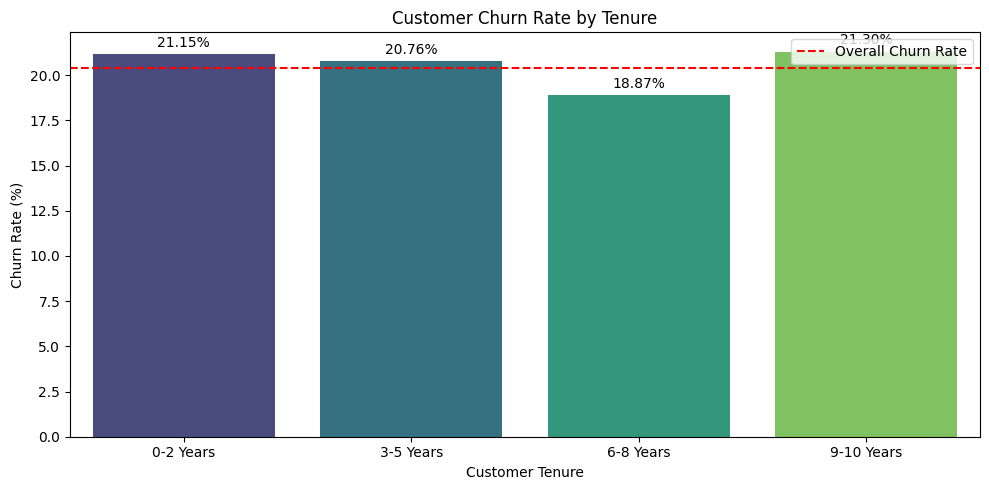

In [40]:

plt.figure(figsize=(10, 5))

tenure_plot = tenure_analysis.reset_index()

ax = sns.barplot(
    data=tenure_plot,
    x='tenure_group',
    y='churn_rate',
    palette='viridis'
)

plt.axhline(
    y=churn_df['churn'].mean() * 100,
    color='red',
    linestyle='--',
    label='Overall Churn Rate'
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.title('Customer Churn Rate by Tenure')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()


In [41]:

age_country_analysis = churn_df.pivot_table(
    index='age_group',
    columns='country',
    values='churn',
    aggfunc='mean',
    observed=False
) * 100

display(age_country_analysis.round(2))


country,France,Germany,Spain
age_group,,,
Under 25,5.91,15.62,8.87
25-34,5.40,12.87,8.14
35-44,14.43,28.37,13.54
45-54,41.64,64.82,38.79
55+,34.12,55.51,29.91


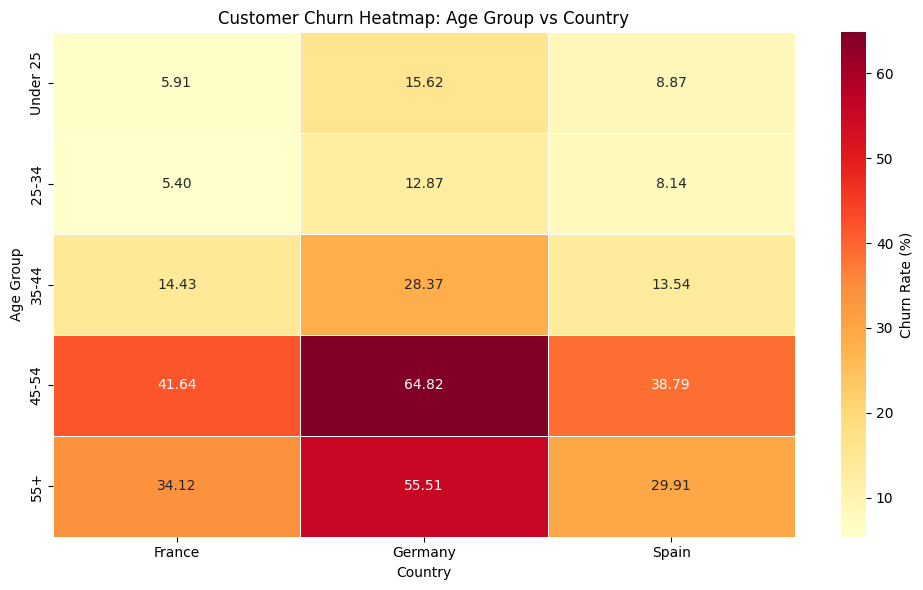

In [42]:

plt.figure(figsize=(10, 6))

sns.heatmap(
    age_country_analysis,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title('Customer Churn Heatmap: Age Group vs Country')
plt.xlabel('Country')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()


In [43]:

product_country_analysis = churn_df.pivot_table(
    index='product_segment',
    columns='country',
    values='churn',
    aggfunc='mean'
) * 100

display(product_country_analysis.round(2))


country,France,Germany,Spain
product_segment,,,
Four Products,100.00,100.00,100.00
Single Product,22.43,42.85,21.87
Three Products,78.85,89.58,78.79
Two Products,5.70,12.12,7.35


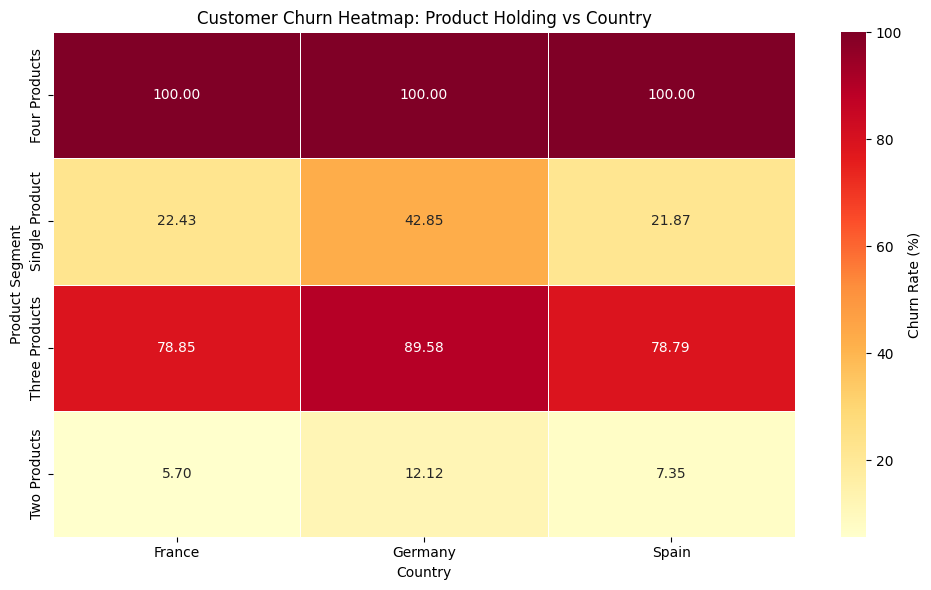

In [44]:

plt.figure(figsize=(10, 6))

sns.heatmap(
    product_country_analysis,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Churn Rate (%)'}
)

plt.title('Customer Churn Heatmap: Product Holding vs Country')
plt.xlabel('Country')
plt.ylabel('Product Segment')
plt.tight_layout()
plt.show()


In [45]:

product_country_counts = churn_df.pivot_table(
    index='product_segment',
    columns='country',
    values='customer_id',
    aggfunc='count',
    fill_value=0
)

display(product_country_counts)


country,France,Germany,Spain
product_segment,,,
Four Products,29,24,7
Single Product,2514,1349,1221
Three Products,104,96,66
Two Products,2367,1040,1183


In [46]:

combined_analysis = churn_df.groupby(
    ['country', 'age_group', 'product_segment'],
    observed=False
).agg(
    total_customers=('customer_id', 'count'),
    churned_customers=('churn', 'sum')
).reset_index()

combined_analysis['churn_rate'] = (
    combined_analysis['churned_customers'] /
    combined_analysis['total_customers']
) * 100

# Sort by highest churn rate
combined_analysis = combined_analysis.sort_values(
    by='churn_rate',
    ascending=False
)

display(combined_analysis.head(20).round(2))


,country,age_group,product_segment,total_customers,churned_customers,churn_rate
36,Germany,55+,Four Products,4,4.0,100.00
22,Germany,Under 25,Three Products,1,1.0,100.00
16,France,55+,Four Products,6,6.0,100.00
52,Spain,45-54,Four Products,4,4.0,100.00
24,Germany,25-34,Four Products,3,3.0,100.00
12,France,45-54,Four Products,10,10.0,100.00
28,Germany,35-44,Four Products,9,9.0,100.00
38,Germany,55+,Three Products,15,15.0,100.00
54,Spain,45-54,Three Products,14,14.0,100.00
8,France,35-44,Four Products,11,11.0,100.00


In [47]:

# Filter segments with at least 30 customers

reliable_segments = combined_analysis[
    combined_analysis['total_customers'] >= 30
].copy()

# Sort by churn rate
reliable_segments = reliable_segments.sort_values(
    by='churn_rate',
    ascending=False
)

# Display the highest-churn segments
display(reliable_segments.head(20).round(2))


,country,age_group,product_segment,total_customers,churned_customers,churn_rate
30,Germany,35-44,Three Products,41,37.0,90.24
10,France,35-44,Three Products,39,30.0,76.92
33,Germany,45-54,Single Product,292,220.0,75.34
37,Germany,55+,Single Product,145,88.0,60.69
13,France,45-54,Single Product,386,205.0,53.11
53,Spain,45-54,Single Product,197,92.0,46.70
17,France,55+,Single Product,230,98.0,42.61
29,Germany,35-44,Single Product,490,189.0,38.57
39,Germany,55+,Two Products,72,24.0,33.33
35,Germany,45-54,Two Products,127,40.0,31.50


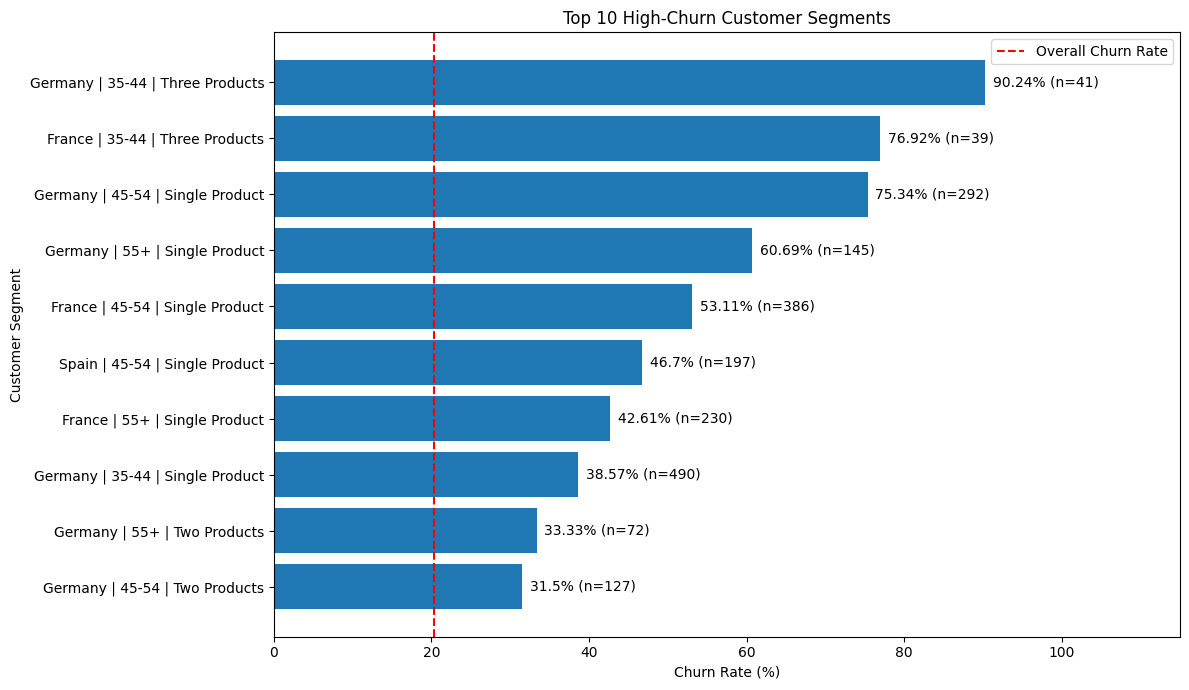

In [48]:

# Select the 10 highest-churn segments
top_segments = reliable_segments.head(10).copy()

# Create readable segment labels
top_segments['segment_label'] = (
    top_segments['country'].astype(str) + ' | ' +
    top_segments['age_group'].astype(str) + ' | ' +
    top_segments['product_segment'].astype(str)
)

# Sort for horizontal chart
plot_data = top_segments.sort_values('churn_rate')

plt.figure(figsize=(12, 7))

bars = plt.barh(
    plot_data['segment_label'],
    plot_data['churn_rate']
)

# Add churn rate and customer count
for bar, (_, row) in zip(bars, plot_data.iterrows()):
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        str(round(row['churn_rate'], 2)) + '% (n=' +
        str(int(row['total_customers'])) + ')',
        va='center'
    )

plt.axvline(
    x=churn_df['churn'].mean() * 100,
    color='red',
    linestyle='--',
    label='Overall Churn Rate'
)

plt.title('Top 10 High-Churn Customer Segments')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Customer Segment')
plt.xlim(0, 115)
plt.legend()
plt.tight_layout()
plt.show()


In [49]:

# Rank customer segments by number of churned customers

contribution_analysis = reliable_segments.copy()

contribution_analysis['churn_contribution'] = (
    contribution_analysis['churned_customers'] /
    churn_df['churn'].sum()
) * 100

contribution_analysis = contribution_analysis.sort_values(
    by='churned_customers',
    ascending=False
)

display(
    contribution_analysis[
        [
            'country',
            'age_group',
            'product_segment',
            'total_customers',
            'churned_customers',
            'churn_rate',
            'churn_contribution'
        ]
    ].head(15).round(2)
)


,country,age_group,product_segment,total_customers,churned_customers,churn_rate,churn_contribution
33,Germany,45-54,Single Product,292,220.0,75.34,10.80
13,France,45-54,Single Product,386,205.0,53.11,10.06
29,Germany,35-44,Single Product,490,189.0,38.57,9.28
9,France,35-44,Single Product,982,188.0,19.14,9.23
17,France,55+,Single Product,230,98.0,42.61,4.81
53,Spain,45-54,Single Product,197,92.0,46.70,4.52
37,Germany,55+,Single Product,145,88.0,60.69,4.32
49,Spain,35-44,Single Product,494,86.0,17.41,4.22
25,Germany,25-34,Single Product,371,72.0,19.41,3.53
5,France,25-34,Single Product,807,65.0,8.05,3.19


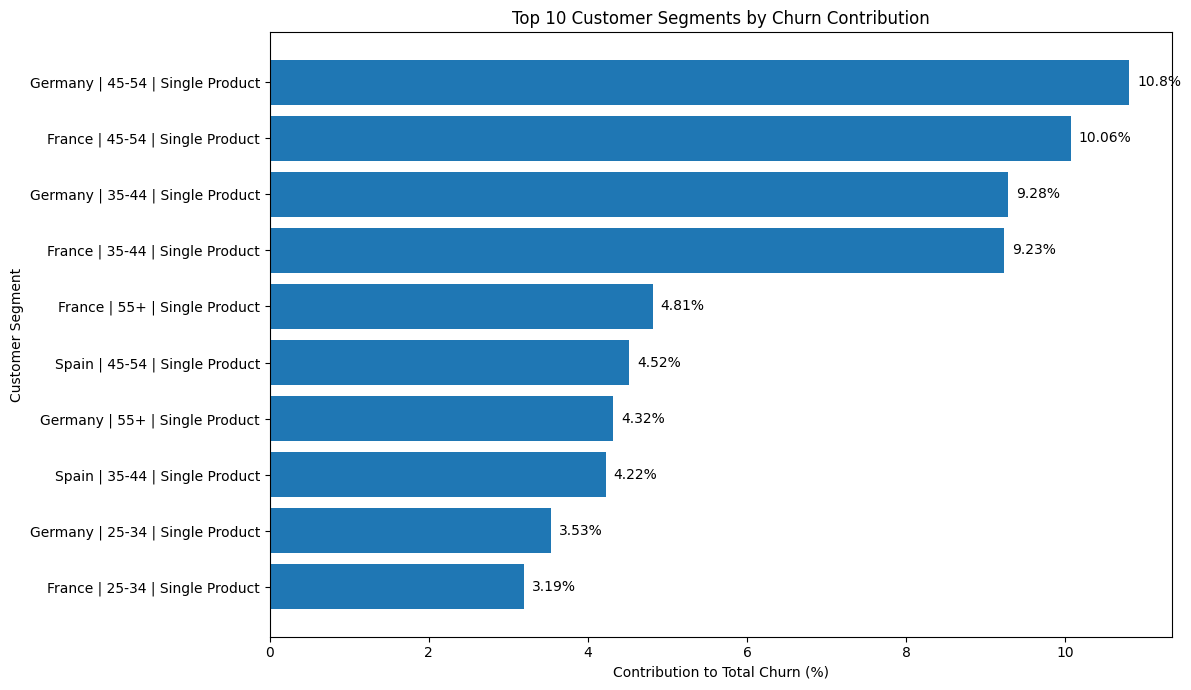

In [50]:

top_contributors = contribution_analysis.head(10).copy()

top_contributors['segment_label'] = (
    top_contributors['country'].astype(str) + ' | ' +
    top_contributors['age_group'].astype(str) + ' | ' +
    top_contributors['product_segment'].astype(str)
)

plot_data = top_contributors.sort_values(
    'churn_contribution'
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    plot_data['segment_label'],
    plot_data['churn_contribution']
)

for bar, (_, row) in zip(bars, plot_data.iterrows()):
    plt.text(
        bar.get_width() + 0.1,
        bar.get_y() + bar.get_height() / 2,
        str(round(row['churn_contribution'], 2)) + '%',
        va='center'
    )

plt.title('Top 10 Customer Segments by Churn Contribution')
plt.xlabel('Contribution to Total Churn (%)')
plt.ylabel('Customer Segment')
plt.tight_layout()
plt.show()


In [51]:

retention_strategy = pd.DataFrame({
    'Customer Segment': [
        'Germany | Age 45-54 | Single Product',
        'France | Age 45-54 | Single Product',
        'Germany | Age 35-44 | Single Product',
        'France | Age 35-44 | Single Product',
        'Germany | Age 35-44 | Three Products'
    ],
    'Identified Risk': [
        'Very high churn rate and high customer loss',
        'High churn rate and high customer loss',
        'Significant customer loss',
        'Large customer base with notable churn contribution',
        'Extremely high churn rate'
    ],
    'Recommended Action': [
        'Conduct targeted retention calls and investigate product suitability',
        'Review customer satisfaction and service experience',
        'Investigate engagement and reasons for account closure',
        'Review customer needs and service quality',
        'Investigate multi-product experience and service issues'
    ],
    'Priority': [
        'Critical',
        'High',
        'High',
        'High',
        'High'
    ]
})

display(retention_strategy)


,Customer Segment,Identified Risk,Recommended Action,Priority
0,Germany | Age 45-54 | Single Product,Very high churn rate and high customer loss,Conduct targeted retention calls and investiga...,Critical
1,France | Age 45-54 | Single Product,High churn rate and high customer loss,Review customer satisfaction and service exper...,High
2,Germany | Age 35-44 | Single Product,Significant customer loss,Investigate engagement and reasons for account...,High
3,France | Age 35-44 | Single Product,Large customer base with notable churn contrib...,Review customer needs and service quality,High
4,Germany | Age 35-44 | Three Products,Extremely high churn rate,Investigate multi-product experience and servi...,High


In [52]:

monitoring_framework = pd.DataFrame({
    'Warning Indicator': [
        'Transaction Activity',
        'Account Balance',
        'Digital Login Activity',
        'Product Engagement',
        'Customer Complaints',
        'Customer Satisfaction'
    ],
    'What to Monitor': [
        'Decline in transaction frequency',
        'Sudden or sustained reduction in balance',
        'Reduced frequency of banking app logins',
        'Decline in usage of banking products',
        'Increase in unresolved complaints',
        'Decrease in customer satisfaction scores'
    ],
    'Monitoring Window': [
        'Rolling 30 days',
        'Rolling 30 days',
        'Rolling 30 days',
        'Rolling 30 days',
        'Rolling 30 days',
        'Latest available survey'
    ],
    'Suggested Retention Action': [
        'Investigate reduced banking activity',
        'Contact customer to understand withdrawal patterns',
        'Offer digital banking assistance',
        'Review product suitability',
        'Escalate unresolved complaints',
        'Conduct customer feedback follow-up'
    ]
})

display(monitoring_framework)


,Warning Indicator,What to Monitor,Monitoring Window,Suggested Retention Action
0,Transaction Activity,Decline in transaction frequency,Rolling 30 days,Investigate reduced banking activity
1,Account Balance,Sudden or sustained reduction in balance,Rolling 30 days,Contact customer to understand withdrawal patt...
2,Digital Login Activity,Reduced frequency of banking app logins,Rolling 30 days,Offer digital banking assistance
3,Product Engagement,Decline in usage of banking products,Rolling 30 days,Review product suitability
4,Customer Complaints,Increase in unresolved complaints,Rolling 30 days,Escalate unresolved complaints
5,Customer Satisfaction,Decrease in customer satisfaction scores,Latest available survey,Conduct customer feedback follow-up


In [53]:

# Create final customer-level dataset

final_df = churn_df.copy()

# Export cleaned and feature-engineered dataset
final_df.to_csv(
    'Bank_Customer_Churn_Cleaned.csv',
    index=False
)

print("Final dataset exported successfully!")
print("Dataset shape:", final_df.shape)
print("\nColumns:")
print(final_df.columns.tolist())


Final dataset exported successfully!
Dataset shape: (10000, 16)

Columns:
['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn', 'age_group', 'tenure_group', 'product_segment', 'balance_segment']


In [54]:

# Export analysis results

age_analysis.to_csv('Age_Churn_Analysis.csv')
product_analysis.to_csv('Product_Churn_Analysis.csv')
geography_analysis.to_csv('Geography_Churn_Analysis.csv')
tenure_analysis.to_csv('Tenure_Churn_Analysis.csv')

combined_analysis.to_csv(
    'Combined_Segment_Analysis.csv',
    index=False
)

contribution_analysis.to_csv(
    'Churn_Contribution_Analysis.csv',
    index=False
)

retention_strategy.to_csv(
    'Retention_Strategy.csv',
    index=False
)

monitoring_framework.to_csv(
    '30_Day_Monitoring_Framework.csv',
    index=False
)

print("All analytical tables exported successfully!")


All analytical tables exported successfully!


In [55]:
import os

print("Current folder:", os.getcwd())
print("\nSaved files:")
print(os.listdir())

Current folder: C:\Users\LENOVO

Saved files:
['-1.14-windows.xml', '.arduinoIDE', '.copilot', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.ms-ad', '.vscode', '.vscode-shared', '30_Day_Monitoring_Framework.csv', 'Age_Churn_Analysis.csv', 'AppData', 'Application Data', 'bank customer churn python-Copy1.ipynb', 'bank customer churn python.ipynb', 'bank customer churn-Copy1.ipynb', 'bank customer churn.ipynb', 'Bank_Customer_Churn_Cleaned.csv', 'Churn_Contribution_Analysis.csv', 'Combined_Segment_Analysis.csv', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'Geography_Churn_Analysis.csv', 'Links', 'Local Settings', 'Microsoft', 'mingw-get-setup.exe', 'Muse Hub', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{aa7e5ac0-1f70-11f0-af2f-b7ff177bb129}.TM.blf', 'NTUSER.DAT{aa7e5ac0-1f70-11f0-af2f-b7ff177bb129}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{aa7e5ac0